# Comparing cosmic ray strategies

Cosmic rays create jumps in the ramps. `mercupix` handles them in two ways:

- **before the fit**: `~mercupix.mask.get_cosmics` flags outliers in the group
  differences and can correct them (inpainting),
- **during the fit**: `~mercupix.fitter.Brandt2024` with `jumps=True` drops the
  one or two consecutive differences that improve the chi-square the most.

This notebook compares how many jumps each finds (completeness), how many
false detections it makes, and how well the flux is recovered, as a function
of the jump amplitude. See {doc}`../methods/jumps` for a summary.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 90

import numpy as np
from mercupix.fitter import Brandt2024
from mercupix.mask import get_cosmics

def simulate(flux=30., ngroups=30, dt=2.8, readnoise=10., npix=64, seed=0):
    rng = np.random.default_rng(seed)
    times = np.arange(1, ngroups + 1, dtype="float32") * dt
    counts = np.cumsum(rng.poisson(flux * dt, (ngroups, npix, npix)), axis=0)
    return times, (counts + rng.normal(0, readnoise, counts.shape)).astype("float32")

## Setup

Half of the pixels get a jump at a random group; the other half are clean and
measure the false detection rate.

In [2]:
flux = 30.
times, clean = simulate(flux)
ngroups, ny, nx = clean.shape
rng = np.random.default_rng(1)
is_hit = rng.random((ny, nx)) < 0.5
hit_group = rng.integers(1, ngroups, (ny, nx))
after_hit = np.arange(ngroups)[:, None, None] >= hit_group[None]

def detect(amplitude, cr_threshold_mad=7, jump_threshold=(20, 30)):
    data = clean + amplitude * (after_hit & is_hit[None])
    # Before the fit: any flagged difference after the first group.
    mask, inpainted = get_cosmics(data, inpaint=True, cr_threshold_mad=cr_threshold_mad)
    found_pre = (mask[1:] > 0).any(axis=0)
    # During the fit: Brandt mask2d counts the kept differences.
    res = Brandt2024(data, times=times, readnoise=10.).fit(jumps=True, jump_threshold=list(jump_threshold))
    found_brandt = res.mask2d < ngroups - 1
    from mercupix.fitter import LSQFit
    slope_pre = LSQFit(inpainted, times=times, degree=1).fit().slope
    return {
        "get_cosmics + LSQ": (found_pre, slope_pre),
        "Brandt2024 (jumps=True)": (found_brandt, res.slope),
    }

## Completeness and false detections

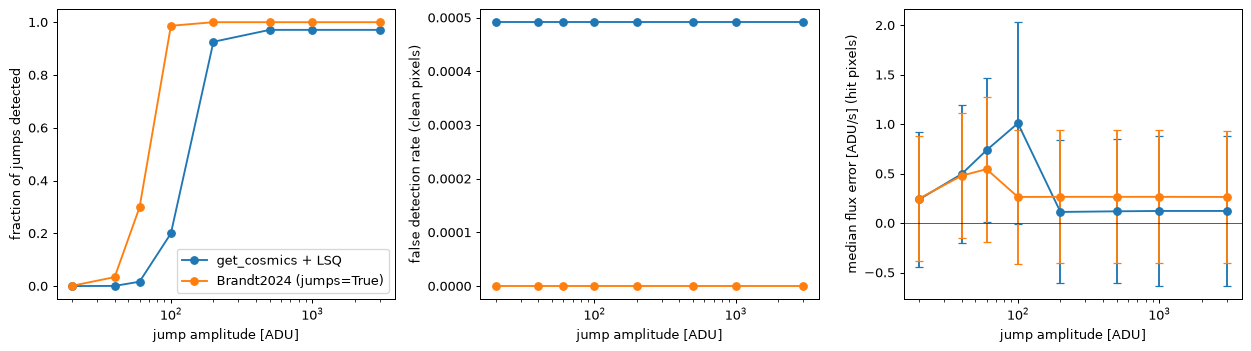

In [3]:
amplitudes = np.array([20, 40, 60, 100, 200, 500, 1000, 3000])
curves = {}
for amp in amplitudes:
    for name, (found, slope) in detect(amp).items():
        c = curves.setdefault(name, dict(complete=[], false=[], bias=[], nmad=[]))
        c["complete"].append(found[is_hit].mean())
        c["false"].append(found[~is_hit].mean())
        d = slope[is_hit] - flux
        c["bias"].append(np.median(d))
        c["nmad"].append(1.4826 * np.median(np.abs(d - np.median(d))))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for name, c in curves.items():
    axes[0].plot(amplitudes, c["complete"], "o-", label=name)
    axes[1].plot(amplitudes, c["false"], "o-", label=name)
    axes[2].errorbar(amplitudes, c["bias"], yerr=c["nmad"], fmt="o-", capsize=3, label=name)
axes[0].set_ylabel("fraction of jumps detected")
axes[1].set_ylabel("false detection rate (clean pixels)")
axes[2].set_ylabel("median flux error [ADU/s] (hit pixels)")
axes[2].axhline(0, color="k", lw=0.5)
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("jump amplitude [ADU]")
axes[0].legend()
fig.tight_layout()
plt.show()

Error bars in the right panel show the normalized median absolute deviation
of the flux error.

- `Brandt2024` detects fainter jumps, because it compares each difference with
  its expected noise (read and photon noise) instead of the robust scatter of
  the ramp.
- Jumps too faint to be detected bias the flux a little, by up to
  `amplitude / exposure time`.
- `get_cosmics` works on any ramp, before any fitter, and also feeds the data
  quality mask. Its detection threshold is set by `cr_threshold_mad`.

## Tuning the thresholds

Both methods trade completeness against false detections. Lower thresholds
detect fainter jumps and make more false detections. The false detection
rate is given in the legend.

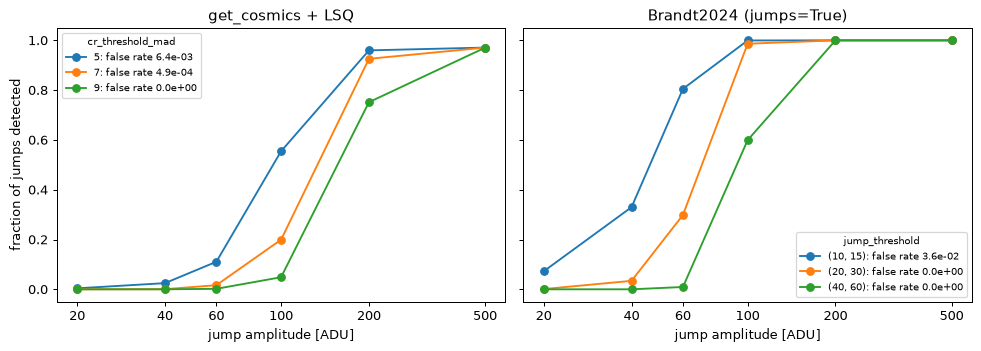

In [4]:
amplitudes = np.array([20, 40, 60, 100, 200, 500])
settings = {
    "get_cosmics + LSQ": [dict(cr_threshold_mad=t) for t in (5, 7, 9)],
    "Brandt2024 (jumps=True)": [dict(jump_threshold=t) for t in ((10, 15), (20, 30), (40, 60))],
}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, kwargs_list) in zip(axes, settings.items()):
    for kwargs in kwargs_list:
        complete, false = [], []
        for amp in amplitudes:
            found, _ = detect(amp, **kwargs)[name]
            complete.append(found[is_hit].mean())
            false.append(found[~is_hit].mean())
        ax.plot(amplitudes, complete, "o-",
                label=f"{list(kwargs.values())[0]}: false rate {np.mean(false):.1e}")
    ax.set_title(name)
    ax.set_xscale("log")
    ax.set_xticks(amplitudes, [str(a) for a in amplitudes])
    ax.minorticks_off()
    ax.set_xlabel("jump amplitude [ADU]")
    ax.legend(fontsize=8, title=list(kwargs.keys())[0], title_fontsize=8)
axes[0].set_ylabel("fraction of jumps detected")
fig.tight_layout()
plt.show()